In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

   car_ID  symboling                       CarName fueltype aspiration  \
0     183          2              vokswagen rabbit   diesel        std   
1     158          0           toyota corolla 1200      gas        std   
2     143          0                    subaru brz      gas        std   
3      84          3                 mitsubishi g4      gas      turbo   
4     184          2  volkswagen 1131 deluxe sedan      gas        std   

  doornumber    carbody drivewheel enginelocation  wheelbase  ...  enginesize  \
0        two      sedan        fwd          front       97.3  ...          97   
1       four  hatchback        fwd          front       95.7  ...          98   
2       four      sedan        fwd          front       97.2  ...         108   
3        two  hatchback        fwd          front       95.9  ...         156   
4        two      sedan        fwd          front       97.3  ...         109   

   fuelsystem  boreratio  stroke compressionratio horsepower  peakrp

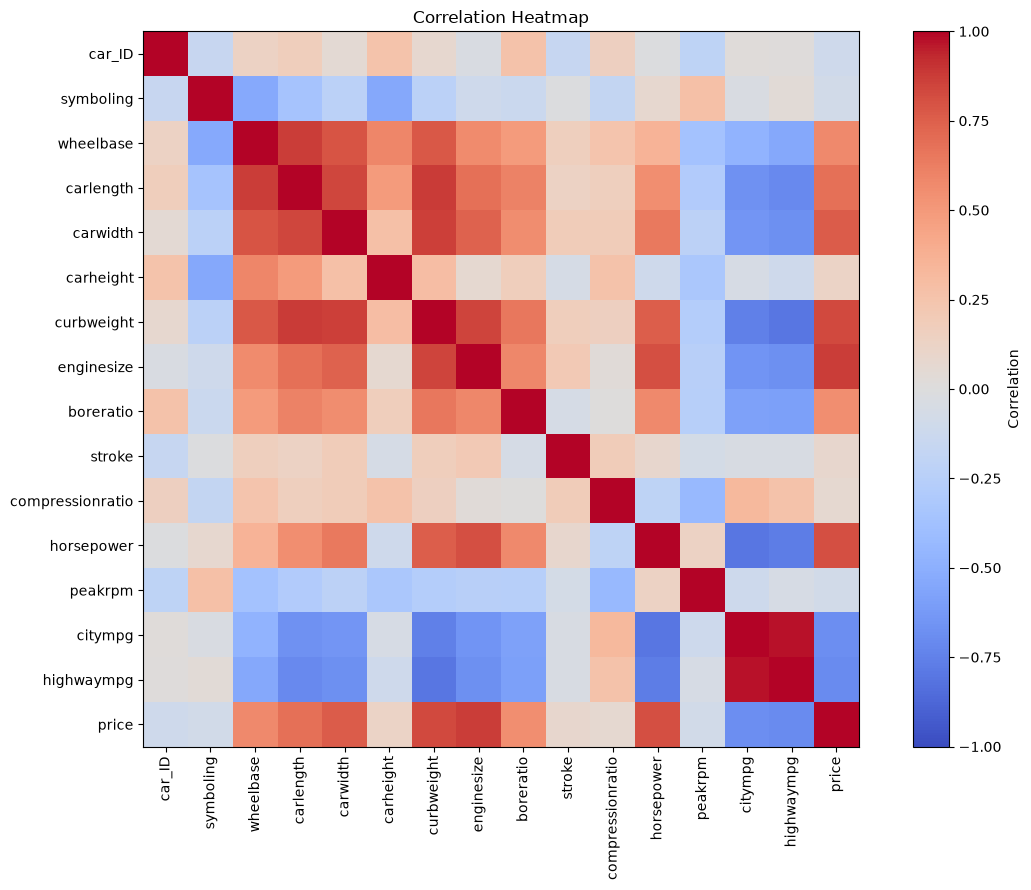

In [147]:
df = pd.read_csv("CarPrice_Assignment.csv")

df = df.sample(frac=1).reset_index(drop=True)
print(df.head())
print(df.shape)

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

plt.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

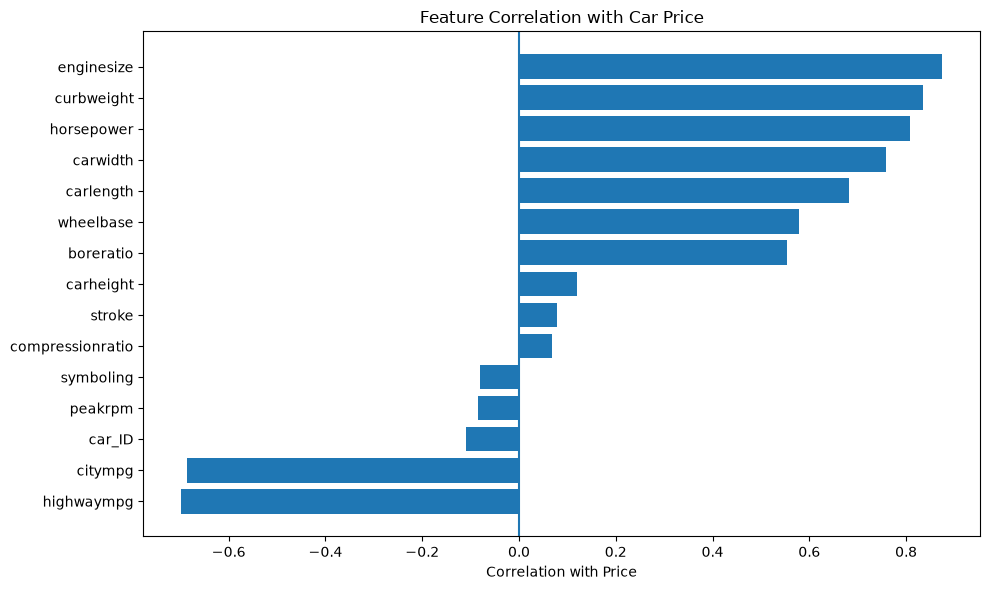

In [148]:
price_correlation = correlation['price'].drop('price')
price_correlation = price_correlation.sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    price_correlation.index,
    price_correlation.values
)

plt.xlabel("Correlation with Price")
plt.title("Feature Correlation with Car Price")
plt.axvline(x=0)

plt.tight_layout()
plt.show()

In [149]:
categorical_columns = [
    'fueltype',
    'aspiration',
    'doornumber',
    'carbody',
    'drivewheel',
    'enginelocation',
    'enginetype',
    'cylindernumber',
    'fuelsystem'
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    dtype=int
)

x = df_encoded.drop(
    columns=['price', 'car_ID', 'CarName']
).values

y = df_encoded['price'].values

print("Input shape:", x.shape)
print("Target shape:", y.shape)

Input shape: (205, 52)
Target shape: (205,)


In [150]:
m = len(x)

split = int(0.8 * m)

x_train = x[:split]
x_test = x[split:]

y_train = y[:split]
y_test = y[split:]

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (164, 52)
Testing data: (41, 52)


In [151]:
x_mean = np.mean(x_train, axis=0)
x_std = np.std(x_train, axis=0)

x_std[x_std == 0] = 1

x_train = (x_train - x_mean) / x_std
x_test = (x_test - x_mean) / x_std

In [152]:
y_mean = np.mean(y_train)
y_std = np.std(y_train)

y_train = (y_train - y_mean) / y_std

In [153]:
n = x_train.shape[1]

w = np.zeros(n)
b = 0

print("Number of features:", n)

Number of features: 52


In [154]:
def compute_cost(x, y, w, b):

    m = x.shape[0]

    total_cost = 0

    for i in range(m):

        f = np.dot(x[i], w) + b

        total_cost += (f - y[i]) ** 2

    return total_cost / (2 * m)

In [155]:
def gradient_descent(x, y, x_test, y_test, w, b, alpha, iterations):
    m = x.shape[0]

    train_cost_history = []
    test_cost_history = []

    for i in range(iterations):
        dj_dw = np.zeros(len(w))
        dj_db = 0

        for j in range(m):
            f = np.dot(x[j], w) + b
            error = f - y[j]

            for k in range(len(w)):
                dj_dw[k] += error * x[j][k]

            dj_db += error

        dj_dw = dj_dw / m
        dj_db = dj_db / m

        for j in range(len(w)):
            w[j] = w[j] - alpha * dj_dw[j]

        b = b - alpha * dj_db

        train_cost_history.append(
            compute_cost(x, y, w, b)
        )

        test_cost_history.append(
            compute_cost(x_test, y_test, w, b)
        )

    return w, b, train_cost_history, test_cost_history

In [156]:
alpha = 0.01
iterations = 500

w = np.zeros(x_train.shape[1])
b = 0

w, b, train_cost_history, test_cost_history = gradient_descent(
    x_train,
    y_train,
    x_test,
    (y_test - y_mean) / y_std,
    w,
    b,
    alpha,
    iterations
)

print("Training complete")

Training complete


In [157]:
cost = compute_cost(x_train, y_train, w, b)

print("Final Cost:", cost)

Final Cost: 0.03220466460258706


In [158]:
alphas = [0.001, 0.01, 0.06]
iteration_values = [500, 1500, 3000]

results_tuning = []

for alpha_value in alphas:
    for iteration_value in iteration_values:

        w_temp = np.zeros(x_train.shape[1])
        b_temp = 0

        w_temp, b_temp, train_cost_temp, test_cost_temp = gradient_descent(
            x_train,
            y_train,
            x_test,
            (y_test - y_mean) / y_std,
            w_temp,
            b_temp,
            alpha_value,
            iteration_value
        )

        test_predictions = np.zeros(len(x_test))

        for i in range(len(x_test)):
            test_predictions[i] = (
                np.dot(x_test[i], w_temp) + b_temp
            )

        test_predictions = test_predictions * y_std + y_mean

        test_rmse_temp = np.sqrt(
            np.mean((y_test - test_predictions) ** 2)
        )

        results_tuning.append([
            alpha_value,
            iteration_value,
            test_rmse_temp
        ])

tuning_df = pd.DataFrame(
    results_tuning,
    columns=['Alpha', 'Iterations', 'Test RMSE']
)

print(tuning_df)

# Find the best combination
best_index = tuning_df['Test RMSE'].idxmin()
best_result = tuning_df.loc[best_index]

print("\nBest Hyperparameters")
print("Alpha:", best_result['Alpha'])
print("Iterations:", best_result['Iterations'])
print("Test RMSE:", best_result['Test RMSE'])


   Alpha  Iterations    Test RMSE
0  0.001         500  2853.038153
1  0.001        1500  2835.653449
2  0.001        3000  2900.960486
3  0.010         500  2918.756785
4  0.010        1500  2841.866944
5  0.010        3000  2763.404710
6  0.060         500  2763.314269
7  0.060        1500  2698.221457
8  0.060        3000  2695.048539

Best Hyperparameters
Alpha: 0.06
Iterations: 3000.0
Test RMSE: 2695.0485393068598


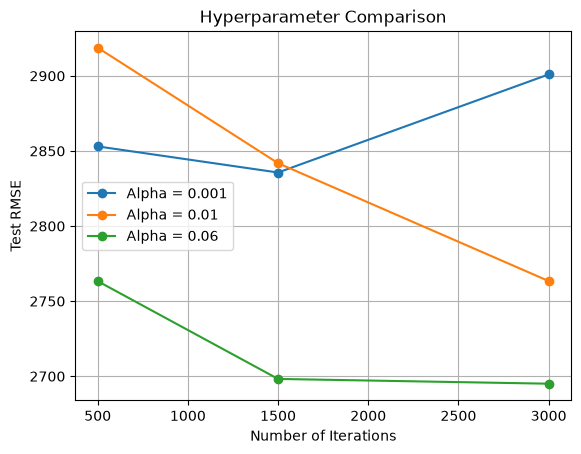

In [159]:
for alpha_value in alphas:

    selected = tuning_df[
        tuning_df['Alpha'] == alpha_value
    ]

    plt.plot(
        selected['Iterations'],
        selected['Test RMSE'],
        marker='o',
        label='Alpha = ' + str(alpha_value)
    )

plt.xlabel("Number of Iterations")
plt.ylabel("Test RMSE")
plt.title("Hyperparameter Comparison")
plt.legend()
plt.grid()
plt.show()

In [160]:
predictions = np.zeros(len(x_test))

for i in range(len(x_test)):

    predictions[i] = np.dot(x_test[i], w) + b

In [161]:
predictions = predictions * y_std + y_mean

In [162]:
results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': predictions
})

print(results.head(10))

   Actual Price  Predicted Price
0        6189.0      6213.079576
1        8845.0     10745.300199
2       14489.0     13536.520607
3        6669.0      6350.858195
4        7603.0      6563.206991
5       15580.0     14712.192367
6        6575.0      5941.548233
7       18950.0     18487.085918
8        8358.0      6524.153908
9       17950.0     15532.977135


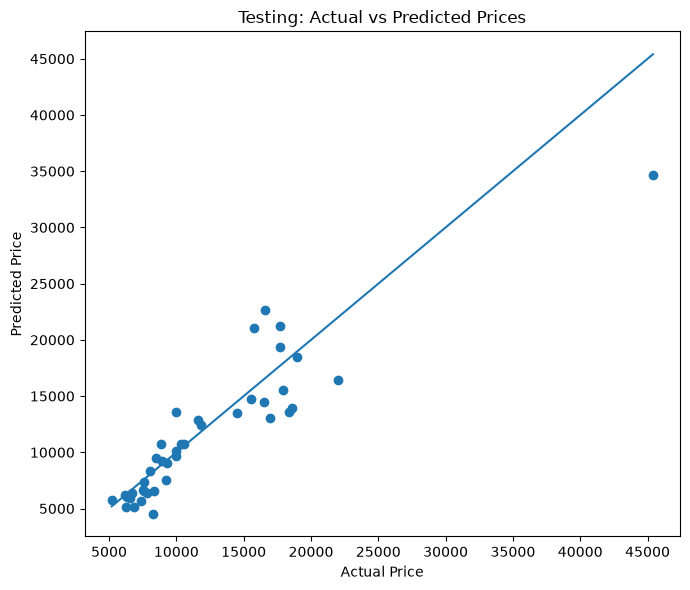

In [163]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, predictions)

plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)]
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Testing: Actual vs Predicted Prices")

plt.tight_layout()
plt.show()

In [164]:
train_predictions = np.zeros(len(x_train))

for i in range(len(x_train)):
    train_predictions[i] = np.dot(x_train[i], w) + b

train_predictions = train_predictions * y_std + y_mean

y_train_original = y_train * y_std + y_mean

train_mae = np.mean(np.abs(y_train_original - train_predictions))

train_mse = np.mean((y_train_original - train_predictions) ** 2)

train_rmse = np.sqrt(train_mse)

train_r2 = 1 - (np.sum((y_train_original - train_predictions) ** 2)
    / np.sum((y_train_original - np.mean(y_train_original)) ** 2))

test_mae = np.mean(np.abs(y_test - predictions))
test_mse = np.mean((y_test - predictions) ** 2)
test_rmse = np.sqrt(test_mse)

test_r2 = 1 - (
    np.sum((y_test - predictions) ** 2)
    / np.sum((y_test - np.mean(y_test)) ** 2)
)

print("TRAINING METRICS")
print("MAE:", train_mae)
print("MSE:", train_mse)
print("RMSE:", train_rmse)
print("R-squared:", train_r2)

print("\nTESTING METRICS")
print("MAE:", test_mae)
print("MSE:", test_mse)
print("RMSE:", test_rmse)
print("R-squared:", test_r2)

TRAINING METRICS
MAE: 1455.804745329799
MSE: 4309933.313934539
RMSE: 2076.037888366814
R-squared: 0.9355906707948258

TESTING METRICS
MAE: 1958.2230445649127
MSE: 8519141.169365702
RMSE: 2918.7567848941612
R-squared: 0.8236458408737083


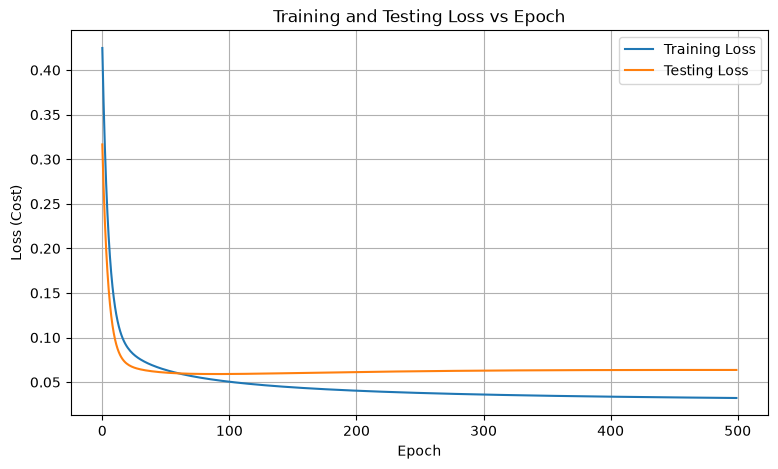

In [165]:
plt.figure(figsize=(9, 5))

plt.plot(train_cost_history, label="Training Loss")
plt.plot(test_cost_history, label="Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss (Cost)")
plt.title("Training and Testing Loss vs Epoch")

plt.legend()
plt.grid()
plt.show()

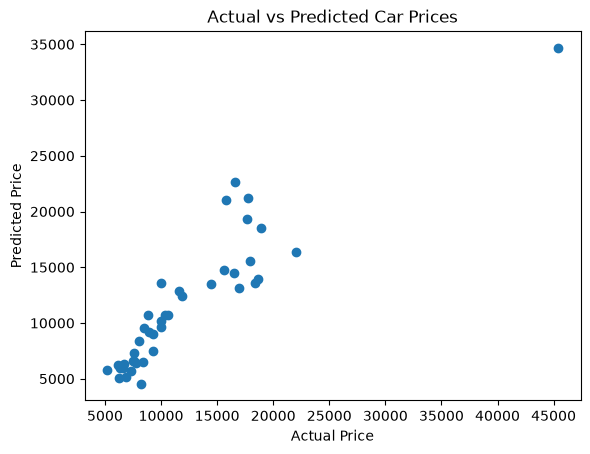

In [166]:
plt.scatter(y_test, predictions)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

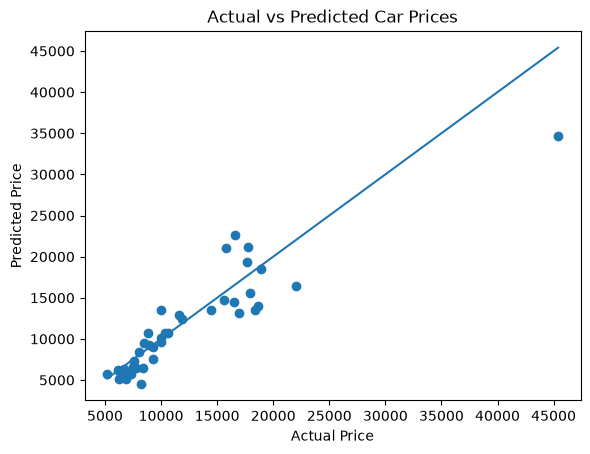

In [167]:
plt.scatter(y_test, predictions)

plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)]
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

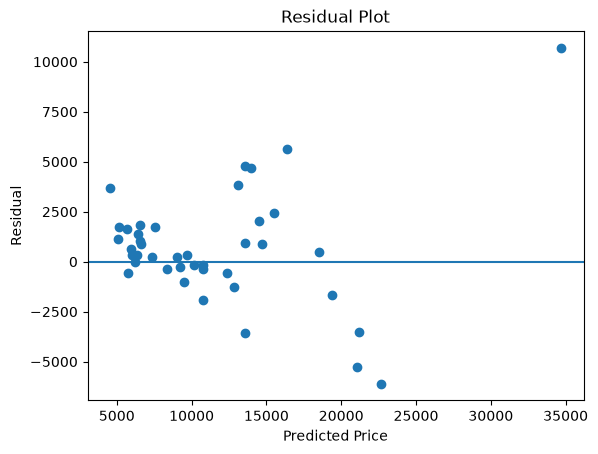

In [168]:
residuals = y_test - predictions

plt.scatter(predictions, residuals)
plt.axhline(y=0)

plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()